# Marimekko (Mosaic) Chart

**Family:** Part-to-whole &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Part-to-whole:* Show how a single entity breaks down into its components.

## Design purpose

A 100% stacked bar chart in which each bar's width is proportional to its total. It shows two part-to-whole splits at once: how big each segment is (width) and how it divides internally (height).

## When to use

- Show market size by segment together with share within each segment
- Show a two-way categorical breakdown (a contingency table) as areas
- Spot which large segments a player is weak in

## Avoid when

- Readers are unfamiliar with it and there is no time to explain it
- There are many columns or many rows (thin slivers become unreadable)

## Alternatives

- 100% stacked bar + separate bar of totals
- Treemap
- Heatmap table

## Design tips

- Label each column with its total so the widths can be checked
- Put the most important segment on the baseline and use gray for 'Other'
- Keep columns and segments to about 5 each so slivers stay readable

## Example

Smartphone market (fictional brands and figures): size of each region (width) and brand share within it (height).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
regions = ["Asia", "Europe", "N. America", "LatAm", "Africa"]
size = pd.Series([620, 210, 170, 120, 80], index=regions)  # units, millions
share = pd.DataFrame({
    "Brand A": [22, 30, 50, 12, 10],
    "Brand B": [20, 33, 25, 28, 22],
    "Brand C": [25, 12, 8, 30, 35],
    "Other":   [33, 25, 17, 30, 33],
}, index=regions)
share.assign(total_units_m=size)

,Brand A,Brand B,Brand C,Other,total_units_m
Asia,22,20,25,33,620
Europe,30,33,12,25,210
N. America,50,25,8,17,170
LatAm,12,28,30,30,120
Africa,10,22,35,33,80


### Plot

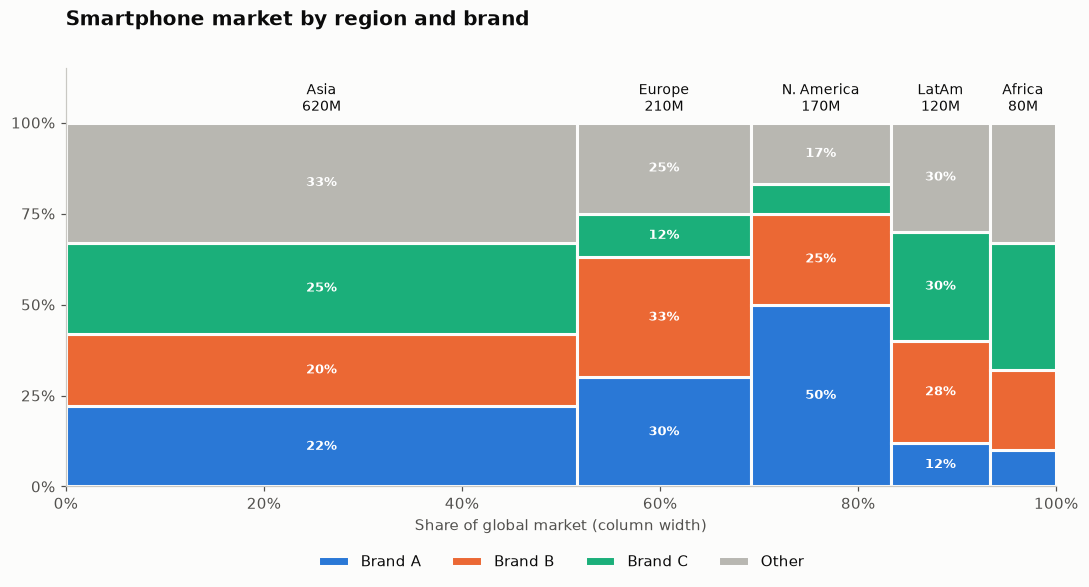

In [3]:
fig, ax = plt.subplots(figsize=(10, 5.5))
widths = size / size.sum() * 100
lefts = np.concatenate([[0], np.cumsum(widths)[:-1]])
colors = PALETTE[:3] + [GRAY]
for x, w, region in zip(lefts, widths, regions):
    bottom = 0
    for j, brand in enumerate(share.columns):
        h = share.loc[region, brand]
        ax.bar(x, h, width=w, bottom=bottom, align="edge", color=colors[j],
               edgecolor="#fcfcfb", linewidth=2, label=brand if region == regions[0] else None)
        if w > 8 and h >= 10:
            ax.text(x + w / 2, bottom + h / 2, f"{h}%", ha="center", va="center",
                    color="white", fontsize=8.5, fontweight="bold")
        bottom += h
    ax.text(x + w / 2, 102, f"{region}\n{size[region]}M", ha="center", va="bottom", fontsize=9)
ax.set_xlim(0, 100)
ax.set_ylim(0, 115)
ax.set_yticks(range(0, 101, 25), [f"{t}%" for t in range(0, 101, 25)])
ax.set_xlabel("Share of global market (column width)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.grid(False)
ax.set_title("Smartphone market by region and brand", pad=28)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.13))
fig.tight_layout()
plt.show()

## How to read it

Column width is a region's share of the global market and segment height is brand share within that region. Each block's area is that brand's share of the global market.

---
Standalone script: [`marimekko.py`](marimekko.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)